# Fake job postings: EDA and preprocessing (notebook 01)

We get to know the EMSCAD dataset before touching any model: class balance, missing
data, duplicates, text lengths and simple spam-style flags, followed by data quality checks on
the text itself and on how related ads would be split. Every section feeds a decision: what to
fix, what to drop, how to split, and which metrics to trust. The second half builds the
preprocessing that notebooks 02 (classical ML) and 03 (deep learning) share: cleaning, engineered
features, the model matrix, and the five saved train/val/test splits.

Run time: about 2 minutes.

In [1]:
import sys, os; os.chdir(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else None; sys.path.insert(0, "."); import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from modules import data_helper as dh
from modules import features as ft
from modules import qc
from modules.classical_runs import get_splits

DATA = "../data/fake_job_postings.csv"

In [2]:
SEEDS = [0, 1, 2, 3, 4]  # one split per seed; every model is evaluated on all five
SEED = 0

dh.seed_everything(SEED)  # Session 5: fix every seed so runs are reproducible
sns.set_theme(style="whitegrid")

## Load and audit the raw data

Load the CSV and run the audit from `modules/data_helper.py`: shape, class counts,
duplicate structure and label conflicts, before we change anything.

In [3]:
df = dh.load_raw(DATA)
a = dh.audit(df)
pd.Series({k: v for k, v in a.items() if k != "missing_rate"}, name="audit").to_frame()

,audit
shape,"[17880, 18]"
class_counts,"{0: 17014, 1: 866}"
positive_rate,0.048434
n_duplicate_rows,281
n_rows_shared_description,4552
n_conflicting_duplicate_groups,0


## Class balance

The target is heavily imbalanced, which drives every later choice of metric and
threshold (Sessions 6/7).

{0: 17014, 1: 866}


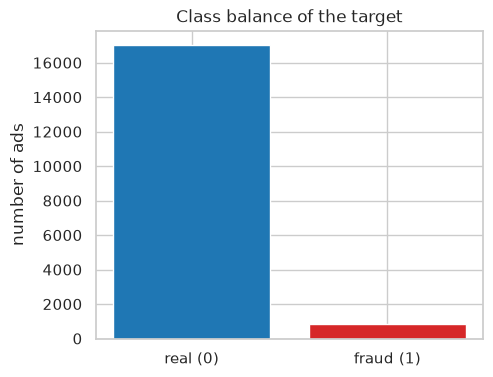

In [4]:
# Count ads per class.
counts = df["fraudulent"].value_counts().sort_index()
print(counts.to_dict())

# Bar chart of the two counts.
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["real (0)", "fraud (1)"], counts.values, color=["tab:blue", "tab:red"])
ax.set_title("Class balance of the target")
ax.set_ylabel("number of ads")
plt.show()

Reading: bar heights are numbers of ads on one shared linear scale; the imbalance
seen here is why accuracy is useless and why PR-AUC plus a validation threshold are
our headline tools.

## Missing values by class

Share of ads missing each column, real versus fraud. A gap between the two bars of
a pair means missingness itself is informative.

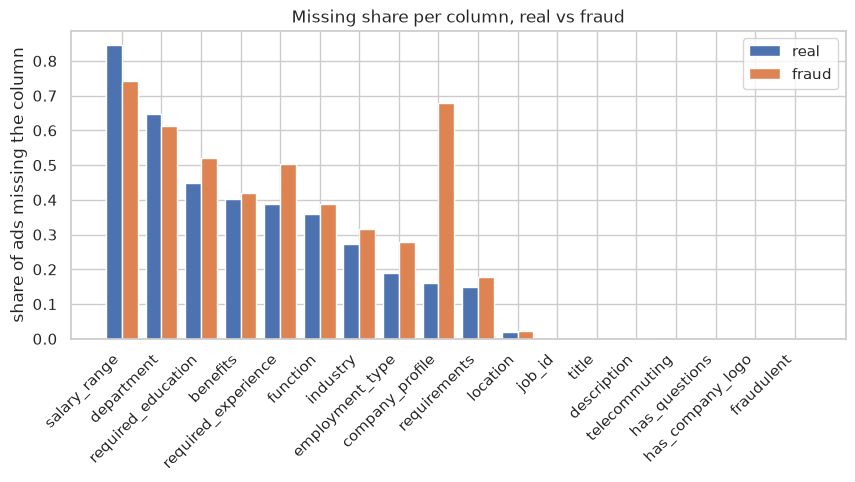

In [5]:
# Share of missing values per column, one column per class, sorted by the real-ad share.
by_class = pd.DataFrame({
    "real": df.loc[df["fraudulent"] == 0].isna().mean(),
    "fraud": df.loc[df["fraudulent"] == 1].isna().mean(),
}).sort_values("real", ascending=False)

# Side-by-side bars: real on the left of each pair, fraud on the right.
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(by_class))
ax.bar(x - 0.2, by_class["real"], 0.4, label="real")
ax.bar(x + 0.2, by_class["fraud"], 0.4, label="fraud")
ax.set_xticks(x, labels=by_class.index, rotation=45, ha="right")
ax.set_ylabel("share of ads missing the column")
ax.set_title("Missing share per column, real vs fraud")
ax.legend()
plt.show()

Reading: a missing company profile is the clearest difference (about two thirds of fraudulent ads
against one in six real ones); employment type, required experience and required education are
also missing more often in fraud. Missingness itself is a signal, so the features keep a
missing-value flag per field instead of imputing the gaps away.

## Duplicates and shared descriptions

The same posting can appear several times (exact duplicates), and different job_ids
can carry the same description text. If copies end up on both sides of a split,
evaluation leaks.

exact duplicate rows (ignoring job_id): 281
rows sharing their description with another row: 4552
duplicate blocks with conflicting labels: 0


largest description group: 380 ads


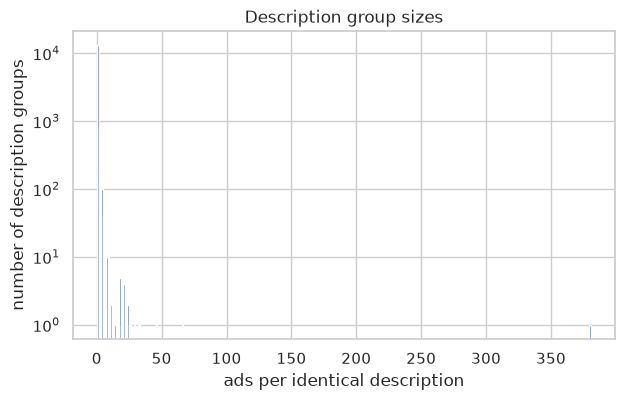

In [6]:
# Duplicate statistics from the audit.
print("exact duplicate rows (ignoring job_id):", a["n_duplicate_rows"])
print("rows sharing their description with another row:", a["n_rows_shared_description"])
print("duplicate blocks with conflicting labels:", a["n_conflicting_duplicate_groups"])

# Group ads by identical (normalised) description: lowercase, collapse whitespace.
desc = (df["description"].fillna("").astype(str).str.lower()
        .str.replace(r"\s+", " ", regex=True).str.strip())
sizes = desc.value_counts()
print("largest description group:", int(sizes.max()), "ads")

# Histogram of group sizes on a log y axis.
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(sizes.values, bins=np.arange(0.5, sizes.max() + 1.5, 1))
ax.set_yscale("log")
ax.set_xlabel("ads per identical description")
ax.set_ylabel("number of description groups")
ax.set_title("Description group sizes")
plt.show()

Reading: most descriptions are unique, but some are repeated tens or hundreds of times (the y
axis is log-scaled). Exact duplicates are dropped, and ads sharing a description must stay on one
side of every split, or a model is tested on copies of its training ads.

## Engineered flags by class

`modules/features.py` adds row-wise flags: missingness indicators, length and
capitalisation cues, and spam cues. Note that the dataset itself already replaced
real URLs, emails and phone numbers with placeholders such as `#URL_ab12cd#`, so the
flags look for those placeholders (plus a few plain-text patterns).

In [7]:
# Engineer the features, then the share of ads firing each binary flag, per class.
feats = ft.add_engineered_features(df)
flags = pd.DataFrame({
    "real": feats.loc[feats["fraudulent"] == 0, ft.BINARY_COLS].mean(),
    "fraud": feats.loc[feats["fraudulent"] == 1, ft.BINARY_COLS].mean(),
}).sort_values("fraud", ascending=False)
flags.round(3)

,real,fraud
missing_company_profile,0.160,0.678
missing_department,0.647,0.613
missing_benefits,0.402,0.420
has_money_words,0.205,0.398
has_company_logo,0.819,0.327
has_url,0.315,0.308
has_questions,0.502,0.289
has_salary,0.155,0.258
has_email,0.068,0.201
missing_requirements,0.149,0.178


Reading: each number is the share of ads in the class where the flag fires. Fraudulent ads lack
a company logo and profile far more often and mention money, email or phone more often; the flags
that differ between the classes are the ones worth keeping as features.

## Fraud rate by country

Only values seen on at least 100 ads, so the rates are not driven by a handful of
rows.

In [8]:
def fraud_rate(col, y, min_n=100):
    """Fraud rate per value of a column, keeping values with at least min_n ads."""
    t = pd.DataFrame({"value": col, "fraud": y}).groupby("value")["fraud"]
    t = t.agg(n="count", fraud_rate="mean")
    return t[t["n"] >= min_n].sort_values("fraud_rate", ascending=False)


fraud_rate(feats["country"], feats["fraudulent"])

,n,fraud_rate
value,,
AU,214,0.186916
US,10656,0.068506
missing,346,0.054913
CA,457,0.026258
IN,276,0.014493
GB,2384,0.009648
PH,132,0.007576
DE,383,0.000000
BE,117,0.000000


## Fraud rate by the categorical columns

Employment type, experience, education, function and industry, with missing as its own value and
only values seen on at least 100 ads.

In [9]:
for col in ["employment_type", "required_experience", "required_education", "function", "industry"]:
    t = fraud_rate(feats[col].fillna("missing"), feats["fraudulent"])
    print(f"{col}: highest and lowest fraud rates (overall {feats['fraudulent'].mean():.3f})")
    print(pd.concat([t.head(4), t.tail(2)]).round(3).to_string(), "\n")

employment_type: highest and lowest fraud rates (overall 0.048)
               n  fraud_rate
value                       
Part-time    797       0.093
missing     3471       0.069
Other        227       0.066
Full-time  11620       0.042
Contract    1524       0.029
Temporary    241       0.008 

required_experience: highest and lowest fraud rates (overall 0.048)
                   n  fraud_rate
value                           
Executive        141       0.071
Entry level     2697       0.066
missing         7050       0.062
Not Applicable  1116       0.054
Internship       381       0.026
Associate       2297       0.018 

required_education: highest and lowest fraud rates (overall 0.048)
                              n  fraud_rate
value                                      
Certification               170       0.112
High School or equivalent  2080       0.082
Master's Degree             416       0.075
missing                    8105       0.056
Associate Degree            274      

Reading: several values are far from the overall rate (for example oil and energy, accounting and
administrative jobs well above it, part-time above full-time), so these columns enter the model as
one-hot (employment type, function, industry) or ordered (experience, education) features.

## Text length of every field

Median length in characters per class, and the share of ads where the field is empty.

In [10]:
rows = {}
for col in dh.TEXT_COLS:
    length = df[col].fillna("").str.len()
    rows[col] = {"median real": length[df["fraudulent"] == 0].median(),
                 "median fraud": length[df["fraudulent"] == 1].median(),
                 "empty % real": round(100 * (length[df["fraudulent"] == 0] == 0).mean(), 1),
                 "empty % fraud": round(100 * (length[df["fraudulent"] == 1] == 0).mean(), 1)}
pd.DataFrame(rows).T

,median real,median fraud,empty % real,empty % fraud
title,25.0,28.0,0.0,0.0
company_profile,588.0,0.0,16.0,67.8
description,1027.0,844.5,0.0,0.1
requirements,476.5,249.0,14.9,17.8
benefits,47.0,36.0,40.2,42.0


Reading: the company profile separates the classes most (empty in most fraudulent ads), and
fraudulent descriptions and requirements are shorter; benefits look the same in both classes. All
five fields are joined into one text column for the models, and the description and title lengths
are kept as numeric features.

## Titles and words

The most common titles among fraudulent ads, and the words whose presence differs most between
the classes (log-odds of an ad containing the word, with add-one smoothing, words in at least 50
ads). This is exploration on all ads; the models only ever learn from their training rows.

In [11]:
titles = df["title"].str.strip().str.lower()
top = titles[df["fraudulent"] == 1].value_counts().head(8)
print(pd.DataFrame({"fraud ads": top, "fraud rate": [df["fraudulent"][titles == t].mean().round(2) for t in top.index]}))

from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer(binary=True, min_df=50, stop_words="english")
X = cv.fit_transform(feats["text"])
y_all = feats["fraudulent"].to_numpy()
in_fraud = (np.asarray(X[y_all == 1].sum(0)).ravel() + 1) / ((y_all == 1).sum() + 2)
in_real = (np.asarray(X[y_all == 0].sum(0)).ravel() + 1) / ((y_all == 0).sum() + 2)
log_odds = pd.Series(np.log(in_fraud / (1 - in_fraud)) - np.log(in_real / (1 - in_real)),
                     index=cv.get_feature_names_out()).sort_values()
print("\nmost fraud-leaning words:", ", ".join(log_odds.tail(15).index[::-1]))
print("most real-leaning words: ", ", ".join(log_odds.head(15).index))

                                                    fraud ads  fraud rate
title                                                                    
administrative assistant                                   21        0.37
data entry admin/clerical positions - work from...         21        1.00
cruise staff wanted *urgent*                               21        1.00
home based payroll typist/data entry clerks pos...         21        1.00
customer service representative                            19        0.29
home based payroll data entry clerk position - ...         12        1.00
data entry                                                 11        0.65
payroll clerk                                              11        1.00



most fraud-leaning words: aker, url_0fa3f7c5e23a16de16a841e368006cae916884407d90b154dfef3976483a71ae, overviewaker, lawson, typist, darren, discoveries, 2500, cuts, refined, referred, faces, wages, represented, recruited
most real-leaning words:  asia, 1500, tefl, tesol, celta, turned, reimbursedexcellent, url_ed9094c60184b8a4975333957f05be37e69d3cdb68decc9dd9a4242733cfd7f7, url_75db76d58f7994c7db24e8998c2fc953ab9a20ea9ac948b217693963f78d2e6b, adkins, cardsgabriel, institute, pitney, bowes, novitex


Reading: the most common fraudulent titles are repeated templates (data entry, payroll clerk,
cruise staff), each posted many times. On the raw text the strongest words are largely artefacts
rather than scam language: a
single company's name (Aker, also glued into "overviewaker"), hashed URLs that identify individual
posters, and the "jobs in Asia, TEFL" template that alone accounts for hundreds of real ads. The
data quality checks below address exactly these: hashed contacts, glued words, and companies or
templates that would otherwise sit on both sides of a split.

## Data quality checks

The sections above look at the columns. These checks look at the content and at how related
ads would be split, using `modules/qc.py`.

### Cells that look filled but are empty

Excel errors such as `#NAME?` and filler such as `.` count as text unless we treat them as
missing.

In [12]:
qc.disguised_missing(df, dh.TEXT_COLS + ["department"])

,NaN,junk,missing % real,missing % fraud
column,,,,
title,0,0,0.0,0.0
company_profile,3308,0,16.0,67.8
description,1,8,0.0,0.1
requirements,2696,38,15.1,18.1
benefits,7212,30,40.4,42.1
department,11547,0,64.7,61.3


### Placeholders and glued text

The dataset replaced every link, email and phone number with a placeholder carrying its own hash
(`#URL_3f9a...#`). A model can memorise one hash, i.e. one poster, instead of learning "has a
phone number". Removed HTML also glued sentences together ("place.We").

In [13]:
raw_text = ft.add_engineered_features(df)["text"]
y_raw = df["fraudulent"]
print(qc.placeholder_counts(raw_text))
glue = qc.glued_boundaries(raw_text)
print(f"ads with glued boundaries: {(glue > 0).sum()} of {len(df)}")

        ads  distinct hashes
URL    5621             1822
EMAIL  1335              392
PHONE   527              159


ads with glued boundaries: 17230 of 17880


Reading: the hashes repeat (more placeholders than distinct hashes), so the same poster's contact
details appear in several ads; cleaning replaces each hash by a generic `#URL`, `#EMAIL` or
`#PHONE`, and glued sentences are separated.

### Companies and near-copies: would related ads end up on both sides of a split?

Two ads can be related without sharing the exact description: the same company (identical
company profile), or the same template with small edits (near-copies, TF-IDF cosine >= 0.9).

In [14]:
company = df["company_profile"].fillna("").str.lower().str.split().str.join(" ")
has_company = company != ""
print("companies with 2+ ads:", qc.group_purity(company[has_company], y_raw[has_company]))

desc = df["description"].fillna("").str.lower().str.split().str.join(" ")
near = qc.near_duplicate_clusters(desc)
other_group = pd.Series(near).groupby(near).transform(lambda s: desc.iloc[s.index].nunique() > 1)
print("ads in a near-copy cluster that spans several exact descriptions:", int(other_group.sum()))

companies with 2+ ads: {'groups with 2+ ads': 1173, 'all fraud': 35, 'all real': 1138, 'mixed': 0}


ads in a near-copy cluster that spans several exact descriptions: 5129


Reading: companies are label-pure (no company has both real and fraudulent ads), so a company seen
in training gives the label away in test. The check below splits the data the way this project
first did, by exact description only, and counts the test ads whose company or near-copy is in the
training rows.

In [15]:
# The first version's grouping: exact (normalised) description only.
old = df.drop_duplicates(subset=[c for c in df.columns if c not in ("job_id", "fraudulent")]).reset_index(drop=True)
old["group"] = old["description"].fillna("").str.lower().str.split().str.join(" ")
old_splits = dh.make_splits(old, seed=SEED)
keys = {"same company": old["company_profile"].fillna("").str.lower().str.split().str.join(" "),
        "near-copy cluster": qc.near_duplicate_clusters(old["group"]).astype(str)}
print(f"exact-description split, seed {SEED}: {len(old_splits['test'])} test ads, "
      f"{int(old['fraudulent'].iloc[old_splits['test']].sum())} test frauds")
qc.split_overlap(old_splits, keys, old["fraudulent"].to_numpy())

exact-description split, seed 0: 3520 test ads, 171 test frauds


,test ads,test frauds
same company,2691,51
near-copy cluster,967,50


### Format and flag checks

Columns the models use only indirectly still need checking: the salary (only "given or not" is
used), location (the country is used), department (only "missing or not" is used), and whether the
engineered flags fire when they should.

In [16]:
sal = df["salary_range"].dropna()
valid = sal.str.fullmatch(r"\d+-\d+")
print(f"salary: {len(sal)} given, {int(valid.sum())} as 'number-number', {int((~valid).sum())} other:",
      sal[~valid].value_counts().head(5).to_dict())
parts = df["location"].dropna().str.split(",").str.len()
print("location: values per number of comma parts", parts.value_counts().sort_index().to_dict())
dept = df["department"].dropna().str.strip()
print(f"department: {dept.nunique()} levels, {dept.str.lower().nunique()} after lower-casing")
text = feats["text"]
for flag, direct in [("has_url", r"#URL|https?://|www\."), ("has_phone", "#PHONE")]:
    print(f"{flag}: flag and direct regex disagree on {int((feats[flag] != text.str.contains(direct).astype(int)).sum())} ads")
words = text[feats["has_money_words"] == 1].str.extract("(" + ft.MONEY_PATTERN + ")", flags=2)[0].str.lower()
print("money-word flag, what it matches:", words.value_counts().to_dict())

salary: 2868 given, 2841 as 'number-number', 27 other: {'10-Oct': 6, '10-Nov': 5, 'Oct-20': 2, '11-Nov': 2, '9-Dec': 1}
location: values per number of comma parts {1: 94, 3: 17320, 4: 104, 5: 7, 6: 4, 7: 2, 9: 1, 11: 1, 16: 1}
department: 1277 levels, 1224 after lower-casing


has_url: flag and direct regex disagree on 0 ads


has_phone: flag and direct regex disagree on 0 ads


money-word flag, what it matches: {'$': 2571, 'per week': 520, 'earn': 306, 'work from home': 184, 'wire': 167, 'no experience': 86}


Reading: the salary column holds dates where Excel converted ranges such as "10-10" (only "salary
given" is used, so this does not reach the models); department and location are messy but only
their missingness and the country are used; the URL and phone flags agree with a direct match; and
the money-word flag fires mostly on the dollar sign, so it is better read as "mentions an amount".

Reading: under exact-description grouping most test ads, and a large share of the test frauds,
have their company or a near-copy in the training rows, so test scores would partly measure
recognising known companies. The cleaning below therefore groups related ads, not only identical
descriptions.

## Cleaning

Session 5: clean first, then split, then fit. `clean` fixes the text (junk cells become missing,
hashed placeholders become generic, glued sentences are separated), drops exact duplicates
(ignoring `job_id`) and gives each ad a `group`: ads sharing an exact description, a company
profile or a near-copy cluster belong to one group, and the relation chains. The splits keep each
group on one side.

In [17]:
dfc = dh.clean(df)
print("rows before cleaning:", len(df), "| after:", len(dfc))
sizes = dfc["group"].value_counts()
print(f"groups: {len(sizes)} | largest: {sizes.max()} ads | groups with 2+ ads:",
      qc.group_purity(dfc["group"], dfc["fraudulent"]))
qc.assert_clean(dfc, dh.TEXT_COLS)
print("checked: no junk cells, hashed placeholders or duplicate ads left after cleaning")

rows before cleaning: 17880 | after: 17596
groups: 4289 | largest: 723 ads | groups with 2+ ads: {'groups with 2+ ads': 1355, 'all fraud': 72, 'all real': 1276, 'mixed': 7}
checked: no junk cells, hashed placeholders or duplicate ads left after cleaning


### Groups with both labels

A group mixes labels when related ads (same company or near-copies) are labelled differently,
which can be a labelling error. They are listed for reading; their labels are kept as given.

In [18]:
g = dfc.groupby("group")["fraudulent"].agg(["size", "mean"])
mixed = g[(g["mean"] > 0) & (g["mean"] < 1)]
print(f"{len(mixed)} mixed groups, {int(mixed['size'].sum())} ads")
for gid, row in mixed.sort_values("size").iterrows():
    ads = dfc[dfc["group"] == gid]
    print(f"- {int(row['size'])} ads, {int(ads['fraudulent'].sum())} fraud | e.g.",
          "; ".join(ads.groupby("fraudulent")["title"].first().str.strip().str[:40]))

7 mixed groups, 298 ads
- 4 ads, 1 fraud | e.g. Admin Assistant; Brand & Logo Design Contest
- 6 ads, 2 fraud | e.g. Data Entry; Data entry
- 11 ads, 1 fraud | e.g. Account Director, Affiliate Network; Quant Analyst
- 18 ads, 2 fraud | e.g. Demonstrator; Bilingual Retail Demonstrator
- 28 ads, 10 fraud | e.g. Immediate Opening : Help Desk /Technical; Urgent Requirement : Senior Exchange & A
- 38 ads, 1 fraud | e.g. Web Designer; Front-End/Java Script Engineer
- 193 ads, 102 fraud | e.g. H1B SPONSOR FOR L1/L2/OPT; IC&E Technician


Reading: almost every group with 2+ ads is label-pure. The mixed ones are few, but one is large: a
chain of related staffing-agency ads of which about half are labelled fraudulent. Keeping each
group on one side of the split is what matters for evaluation, so the labels are kept as given.

### Save the processed data

Every later notebook (and the GPU server) reads this file instead of cleaning the raw CSV again,
so all of them use exactly the same rows, text and groups.

In [19]:
dh.save_processed(dfc)
assert dh.load_processed().equals(dfc), "the saved file must read back identically"
print("saved", dh.PROCESSED, f"({os.path.getsize(dh.PROCESSED) / 1e6:.1f} MB)")

saved ../data/processed/emscad_clean.csv.gz (15.8 MB)


## Feature engineering

`add_engineered_features` adds the joined `text` column (title, company profile,
description, requirements, benefits), missing-value flags, length and capitalisation
statistics, and spam cues. These are computed row by row from the ad itself, so they
cannot leak information between splits.

In [20]:
dfe = ft.add_engineered_features(dfc)
new_cols = [c for c in dfe.columns if c not in df.columns]
print(len(new_cols), "new columns:", ", ".join(new_cols))
dfe[["title", "text"] + ft.NUMERIC_COLS[:3]].head(3)

16 new columns: group, text, country, has_salary, missing_company_profile, missing_requirements, missing_benefits, missing_department, desc_len, title_len, n_exclaim, n_upper_ratio, has_url, has_email, has_phone, has_money_words


,title,text,desc_len,title_len,n_exclaim
0,Marketing Intern,"Marketing Intern We're Food52, and we've creat...",912,16,1
1,Customer Service - Cloud Video Production,Customer Service - Cloud Video Production 90 S...,2016,41,5
2,Commissioning Machinery Assistant (CMA),Commissioning Machinery Assistant (CMA) Valor ...,355,39,0


## Splits: by group of related ads, saved for all seeds

`make_splits` uses `StratifiedGroupKFold` on the group id (60/20/20, class ratio kept), so related
ads can never sit in two splits. Each seed's indices are saved to `splits/` with a fingerprint of
the cleaned data and its groups; every notebook and every machine reloads exactly these rows, and
splits made under another grouping are refused.

In [21]:
y = dfe["fraudulent"].to_numpy()

# One row per (seed, split): size and fraud count.
rows = []
for seed in SEEDS:
    splits = get_splits(dfe, seed)  # loads splits/seed<N>.npz, creating it the first time
    for name, idx in splits.items():
        rows.append({"seed": seed, "split": name, "rows": len(idx),
                     "fraud": int(y[idx].sum()), "fraud rate": round(float(y[idx].mean()), 4)})

# Pivot to one line per seed.
pd.DataFrame(rows).pivot(index="seed", columns="split", values=["rows", "fraud"])

rows              fraud           
split  test  train   val  test train  val
seed                                     
0      3519  10558  3519   171   514  171
1      3519  10558  3519   171   514  171
2      3519  10558  3519   171   514  171
3      3519  10558  3519   171   514  171
4      3519  10558  3519   171   514  171

In [22]:
for seed in SEEDS:
    splits = get_splits(dfe, seed)

    # Description groups present in each split.
    groups = {name: set(dfe["group"].iloc[idx]) for name, idx in splits.items()}

    # No group may appear in two splits (otherwise copies of an ad leak across the split).
    for a_name, b_name in (("train", "val"), ("train", "test"), ("val", "test")):
        shared = groups[a_name] & groups[b_name]
        assert not shared, f"seed {seed}: {len(shared)} groups shared by {a_name} and {b_name}"
print("checked: no group appears in two splits, for every seed")

# The leak measured above under the old grouping, now on the saved splits: must be zero.
norm = lambda s: s.fillna("").str.lower().str.split().str.join(" ")
keys = {"same company": norm(dfe["company_profile"]),
        "near-copy cluster": qc.near_duplicate_clusters(norm(dfe["description"])).astype(str)}
for seed in SEEDS:
    ov = qc.split_overlap(get_splits(dfe, seed), keys, y)
    assert ov["test ads"].sum() == 0, f"seed {seed}: related ads cross from train to test: {ov.to_dict()}"
print("checked: no test ad shares its company or near-copy cluster with a training ad, for every seed")

checked: no group appears in two splits, for every seed


checked: no test ad shares its company or near-copy cluster with a training ad, for every seed


## The model matrix (fitted on the training rows only)

`make_preprocessor` is one `ColumnTransformer`: TF-IDF over the joined text, one-hot
metadata, ordinal levels, scaled numeric statistics and the binary flags. Session 5: it
is fitted on the training rows only and then applied to validation and test.

In [23]:
split0 = get_splits(dfe, SEED)

# Fit on the training rows only, then transform validation with the fitted vocabulary and scales.
pre = ft.make_preprocessor()
X_train = pre.fit_transform(dfe.iloc[split0["train"]])
X_val = pre.transform(dfe.iloc[split0["val"]])
names = pre.get_feature_names_out()
print("train matrix:", X_train.shape, "| validation matrix:", X_val.shape)

# Columns contributed by each block of the ColumnTransformer.
pd.Series([n.split("__")[0] for n in names]).value_counts().rename("columns per block").to_frame()

train matrix: (10558, 20125) | validation matrix: (3519, 20125)


,columns per block
text,20000
nominal,107
binary,12
numeric,4
ordinal,2


## What the EDA tells us to do

| Finding | Decision |
|---|---|
| 4.8% of ads are fraudulent | PR-AUC as the main metric, threshold chosen on validation, class weights |
| Exact duplicates and repeated descriptions | Drop duplicates; keep each description on one side of a split |
| Companies are label-pure; templates recur with small edits | Group ads by description, company and near-copy before splitting |
| Missing fields, logo, money and contact cues differ by class | Missing-value flags and spam-cue flags as features |
| Categorical values with very different fraud rates | One-hot and ordered metadata features |
| Some countries have no fraud at all | Keep country, but read it as a collection artefact |
| Junk cells, hashed contacts, glued sentences | Clean the text before any model sees it |
| Salary values corrupted by Excel; messy department and location | Use only "salary given", the country code and "department missing" |
| Every model must see the same rows | Save the processed data and the splits; fit transformers on training rows only |